# Regularization: shrinkage and sparsity

A companion to Lecture 14

Marcel Turcotte  
2026-10-27

This notebook isolates the effect of L1 and squared L2 penalties in
linear regression. We know the true coefficients of the synthetic data,
so we can compare them with ordinary least squares (OLS), Ridge, and
Lasso. OLS is the unregularized baseline; Ridge and Lasso apply L2 and
L1 regularization, respectively. Lecture 14 applies the same penalty
ideas to neural-network weights.

The purpose is to distinguish **shrinkage** from **sparsity**. This
experiment does not establish which estimator predicts best on unseen
data.

## Data and models

Fifteen features are generated, but only three have nonzero true
coefficients. We standardize each feature to zero sample mean and unit
sample variance before fitting the models. The generated features
already have comparable scales, so standardization makes only a small
numerical difference here; it makes the preprocessing assumption
explicit.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler

X, y, true_coef = make_regression(n_samples=200, n_features=15, n_informative=3,
                                 noise=10.0, coef=True, random_state=42)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Express the known coefficients in the same coordinates as the fitted models.
true_coef_scaled = true_coef * scaler.scale_
coefficient_models = {
    'OLS': LinearRegression().fit(X_scaled, y),
    'Ridge (L2)': Ridge(alpha=10.0).fit(X_scaled, y),
    'Lasso (L1)': Lasso(alpha=10.0).fit(X_scaled, y)
}

## Why standardize?

Feature units affect coefficient penalties. Multiplying a feature’s
values by 100 allows its coefficient to be divided by 100 while
preserving the same predictions, but changes the penalty on that
coefficient. Standardization puts the penalties on a common scale across
features. It does not itself create the sparsity associated with L1
regularization. See the <a
href="https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html"
class="external" data-icon="true">StandardScaler documentation</a>.

For a feature transformed as $x'_j=(x_j-\mu_j)/s_j$, its coefficient in
standardized coordinates is $w'_j=s_jw_j$. Centering is absorbed by the
fitted intercept. The plot and table below compare **true and estimated
coefficients in these same standardized coordinates**: each coefficient
describes the predicted change in the target for a
one-standard-deviation increase in its feature, holding the other
features fixed.

All generated observations are used as training data for this
coefficient demonstration. When evaluating prediction on held-out data,
fit the scaler only on training data and reuse it to transform
validation and test data; a scikit-learn pipeline keeps that
preprocessing with the model.

## Compare coefficients

The informative and irrelevant features use **separate vertical
scales**. The expanded scale in the lower panel makes small nonzero
coefficients visible. Hollow circles identify coefficients that are
exactly zero, measured before display rounding.

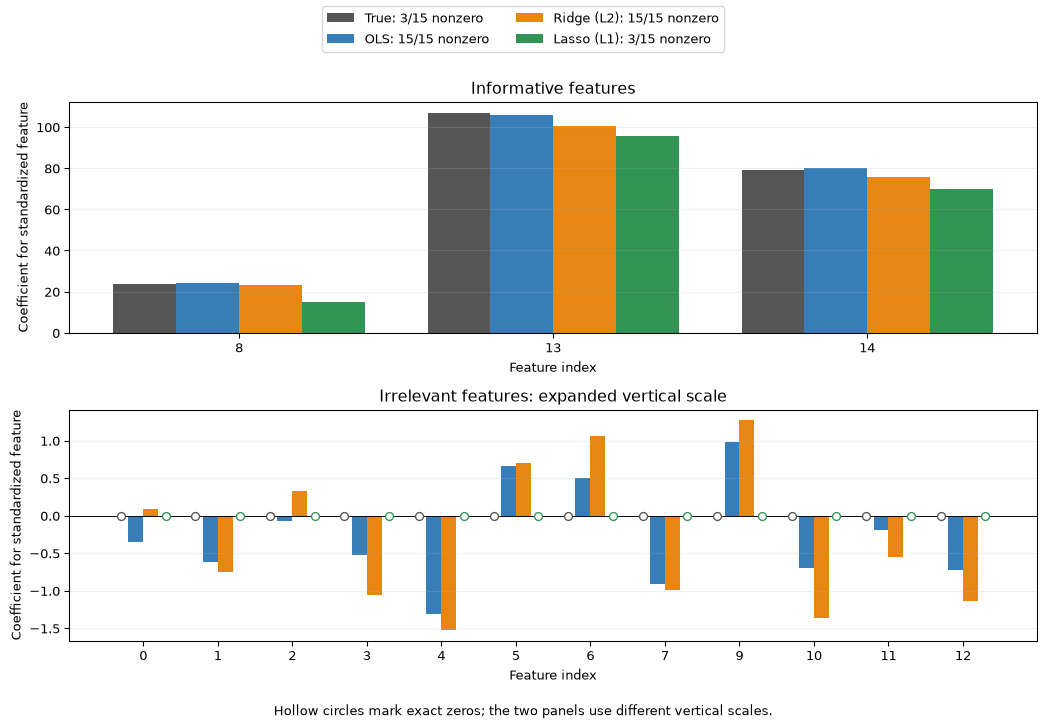

In [2]:
series = [('True', true_coef_scaled)] + [
    (name, fitted.coef_) for name, fitted in coefficient_models.items()
]
colors = ['#555555', '#377eb8', '#e68613', '#319354']
groups = [
    (true_coef != 0, 'Informative features'),
    (true_coef == 0, 'Irrelevant features: expanded vertical scale')
]
fig, axes = plt.subplots(2, 1, figsize=(11, 7.5))
for ax, (mask, title) in zip(axes, groups):
    feature_indices = np.flatnonzero(mask)
    positions = np.arange(len(feature_indices))
    for offset, ((name, values), color) in enumerate(zip(series, colors)):
        x_positions = positions + (offset-1.5)*0.2
        nonzero = np.count_nonzero(values)
        ax.bar(x_positions, values[mask], width=0.2, color=color,
               label=f'{name}: {nonzero}/15 nonzero')
        zeros = values[mask] == 0
        ax.scatter(x_positions[zeros], values[mask][zeros], s=35,
                   facecolors='white', edgecolors=color, zorder=4)
    ax.set(xticks=positions, xticklabels=feature_indices, xlabel='Feature index',
           ylabel='Coefficient for standardized feature', title=title)
    ax.axhline(0, color='black', linewidth=0.7)
    ax.grid(axis='y', alpha=0.2)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=2)
fig.text(0.5, 0.01, 'Hollow circles mark exact zeros; the two panels use different vertical scales.',
         ha='center')
fig.tight_layout(rect=(0, 0.035, 1, 0.91))
plt.show()

In [3]:
print(f"{'Feature':<9} {'True':>10} {'OLS':>10} {'Ridge':>10} {'Lasso':>10}")
for index, value in enumerate(true_coef_scaled):
    estimates = [fitted.coef_[index] for fitted in coefficient_models.values()]
    print(f"{index:<9} {value:>10.2f}" + ''.join(f'{estimate:>10.2f}' for estimate in estimates))

print('\nCounts and sparsity, measured before rounding:')
print(f"{'Estimator':<12} {'Nonzero':>9} {'Exactly zero':>14} {'Sparsity':>11}")
for name, fitted in coefficient_models.items():
    nonzero = np.count_nonzero(fitted.coef_)
    zeros = len(fitted.coef_) - nonzero
    sparsity = 100*zeros/len(fitted.coef_)
    print(f'{name:<12} {nonzero:>9} {zeros:>14} {sparsity:>10.1f}%')
print('True informative indices:', np.flatnonzero(true_coef))
print('Lasso nonzero indices:   ', np.flatnonzero(coefficient_models['Lasso (L1)'].coef_))

Feature         True        OLS      Ridge      Lasso
0               0.00     -0.35      0.09      0.00
1               0.00     -0.62     -0.75     -0.00
2               0.00     -0.07      0.33      0.00
3               0.00     -0.53     -1.06     -0.00
4               0.00     -1.31     -1.52     -0.00
5               0.00      0.66      0.71      0.00
6               0.00      0.50      1.07      0.00
7               0.00     -0.91     -0.98     -0.00
8              23.71     24.13     23.25     15.02
9               0.00      0.98      1.27      0.00
10              0.00     -0.70     -1.36     -0.00
11              0.00     -0.19     -0.55     -0.00
12              0.00     -0.72     -1.13     -0.00
13            106.95    105.85    100.34     95.86
14             79.06     79.87     75.69     69.79

Counts and sparsity, measured before rounding:
Estimator      Nonzero   Exactly zero    Sparsity
OLS                 15              0        0.0%
Ridge (L2)          15           

With these fixed settings, OLS and Ridge retain fifteen nonzero
coefficients and Lasso retains three, giving 80% exact-zero sparsity.
Here Lasso selects the three informative features. This is an
illustration, not a guarantee of recovering true features in other
datasets, particularly when predictors are correlated.

L2 encourages smaller weights collectively and generally retains a dense
solution. It penalizes the total squared coefficient magnitude; an
individual coefficient need not become smaller than its OLS estimate
when predictors are correlated. Even independently generated features
have some correlation in a finite sample.

L1 encourages sparsity: the corner of the absolute-value penalty at zero
allows the optimum to have exactly zero coefficients, and Lasso’s
coordinate-descent solver can find these sparse solutions. These zeros
are a property of the optimization problem. Display rounding is not used
to decide whether a coefficient is zero. See the <a
href="https://scikit-learn.org/stable/modules/linear_model.html#lasso"
class="external" data-icon="true">Lasso user guide</a>.

## What do the penalty coefficients mean?

The two `alpha=10` values were chosen for a qualitative demonstration.
They are not matched penalty strengths. <a
href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html"
class="external" data-icon="true">Ridge</a> minimizes

$$
\|y-Xw\|_2^2+\alpha\|w\|_2^2,
$$

whereas <a
href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html"
class="external" data-icon="true">Lasso</a> minimizes

$$
\frac{1}{2N}\|y-Xw\|_2^2+\alpha\|w\|_1.
$$

Here $X$ denotes the standardized feature matrix and $w$ its
coefficients. The fitted intercept is omitted from these compact
expressions and is not penalized. Different data-loss normalizations and
penalty definitions mean that coefficients from different APIs need
interpretation before comparison.

## Connection to neural networks

The penalty idea extends to entries of the neural network’s weight
matrices. In `SimpleMLP`, the objective is mean BCE plus $\lambda/2$
times the sum of squared weights, and the added gradient is $\lambda W$.
Biases are not penalized.

L1 encourages sparse connections in a neural network, but ordinary
gradient updates need not return exact zeros. An input feature is fully
disconnected only when all of its outgoing weights are zero; a single
zero connection does not establish feature removal.

## What this experiment establishes

The figures illustrate coefficient shrinkage and sparsity. The three
estimators retain different numbers of features; similar-looking
coefficients on the informative features do not establish equal
predictive performance. Nor does a sparser model automatically predict
better.

To compare prediction on unseen examples, use separate training,
validation, and test data, choose each estimator’s penalty using
validation results, and report final test errors. Regularization that is
too strong can underfit. The fixed penalty values here serve the
coefficient demonstration and have not been selected for prediction
accuracy.

[Return to Lecture 14](index.qmd).